<a href="https://colab.research.google.com/github/Yireh111/MachineLearning/blob/main/UnidadII/PRACTICA_FINAL_U2_SVR_EQUIPO_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRACTICA FINAL U2

## Comparación de Modelos de Machine Learning para Predicción de Precios de Autos

**Algoritmo asignado:** Support Vector Regression (SVR)  
**Equipo:** 3

### Integrantes
- Josue Ulises Rios Garcia
- Gael Yireh Benitez Medina
- Angel Zaid Gamiz Reyes
- Jaime Alejandro Frayre Salazar

## 1. Librerías y carga del dataset

Se importan las librerías necesarias para el procesamiento de los datos, entrenamiento de los modelos SVR y evaluación de sus resultados. Posteriormente, se carga el dataset de automóviles utilizado para predecir la variable `price`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

df = pd.read_csv("autos2.csv")

print("Dataset cargado correctamente")
print("Dimensiones:", df.shape)
display(df.head())

Dataset cargado correctamente
Dimensiones: (201, 32)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,peak-rpm,city-mpg,highway-L/100km,price,city-L/100km,fuel-type_code,diesel,gas,fuel-type-map,horsepower-binned
0,3,122,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,5000.0,21,8.703704,13495.0,11.190476,1,False,True,1,Low
1,3,122,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,5000.0,21,8.703704,16500.0,11.190476,1,False,True,1,Low
2,1,122,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,5000.0,19,9.038462,16500.0,12.368421,1,False,True,1,Medium
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,5500.0,24,7.833333,13950.0,9.791667,1,False,True,1,Low
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,5500.0,18,10.681818,17450.0,13.055556,1,False,True,1,Low


## 2. Construcción y evaluación de los modelos SVR

Se define una función para entrenar y evaluar los diferentes modelos SVR. Para cada modelo se utiliza la misma división de 80% para entrenamiento y 20% para prueba, además de aplicar escalamiento a las variables predictoras.

Se calculan las métricas R² en entrenamiento, R² en prueba, MSE y RMSE para comparar el desempeño de cada configuración.

In [ ]:
resultados = []
predicciones = {}

def correr_svr(nombre, variables, verbose=True, **params):

    # Variables predictoras y variable objetivo
    X = df[variables]
    y = df["price"]

    # División 80% entrenamiento y 20% prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    # Escalamiento y modelo SVR
    modelo = make_pipeline(
        StandardScaler(),
        SVR(**params)
    )

    # Entrenamiento
    modelo.fit(X_train, y_train)

    # Evaluación
    r2_train = modelo.score(X_train, y_train)

    y_pred = modelo.predict(X_test)
    r2_test = modelo.score(X_test, y_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    # Cantidad de vectores soporte
    n_sv = modelo.named_steps["svr"].support_.shape[0]

    if verbose:
        print(f"\n########################## {nombre} ##########################")
        print(f"Resultados de {nombre} con {params}")
        print("Variables:", variables)

        print("\nR² en entrenamiento:", r2_train)
        print("R² en prueba:", r2_test)
        print(f"MSE: {mse:.2f}")
        print(f"RMSE: {rmse:.2f}")
        print(f"Vectores soporte: {n_sv} de {len(X_train)} datos de entrenamiento")

    # Guardar resultados
    global resultados
    resultados = [
        r for r in resultados
        if r["algoritmo"] != nombre
    ]

    resultados.append({
        "algoritmo": nombre,
        "variables": ", ".join(variables),
        **params,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "mse": mse,
        "rmse": rmse,
        "vectores_soporte": n_sv
    })

    # Guardar predicciones para las gráficas
    predicciones[nombre] = (y_test, y_pred)

    return modelo

print("Constructor SVR creado correctamente")

Constructor SVR creado correctamente


## 3. Configuración y entrenamiento de 30 modelos SVR

Se generan 30 modelos SVR diferentes mediante distintas combinaciones de variables predictoras y parámetros. Se modifican características como el kernel, C, epsilon, gamma y, en algunos casos, el grado del kernel polinómico.

Esto permite evaluar cómo los cambios en las variables y en la configuración del modelo afectan su desempeño.

In [ ]:
# Modelo SVR 1
m1 = correr_svr(
    "SVR 1",
    ["horsepower", "engine-size", "bore", "stroke", "compression-ratio"],
    kernel="rbf",
    C=50000,
    epsilon=100,
    gamma="scale"
)

# Abreviaturas de las variables
HP = "horsepower"
ES = "engine-size"
CW = "curb-weight"
WB = "wheel-base"
CM = "city-mpg"

BO = "bore"
ST = "stroke"
CR = "compression-ratio"
RPM = "peak-rpm"

WI = "width"
LE = "length"
HE = "height"

# Modelos SVR 2 al 30
ALGORITMOS = [
    ("SVR 2",  [HP, ES, CW],                 dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 3",  [HP, ES, CW, WB],             dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 4",  [HP, ES, CW, WB, CM],         dict(kernel="rbf", C=100000, epsilon=1000)),
    ("SVR 5",  [HP, ES, CM, WB, BO, CW],     dict(kernel="rbf", C=50000, epsilon=500)),
    ("SVR 6",  [ES, CW],                     dict(kernel="rbf", C=30000, epsilon=1000)),
    ("SVR 7",  [HP, ES, CW, WI, LE],         dict(kernel="rbf", C=100000, epsilon=1000)),
    ("SVR 8",  [HP, CW, WB, WI, LE, CM],     dict(kernel="rbf", C=50000, epsilon=500)),
    ("SVR 9",  [HP, ES, CW, WB, WI, LE, CM], dict(kernel="rbf", C=100000, epsilon=1000, gamma=0.05)),
    ("SVR 10", [HP, ES, CW, WB, LE, WI, HE, BO, ST, CR, RPM, CM],
                                             dict(kernel="rbf", C=100000, epsilon=1000)),
    ("SVR 11", [ES, BO, ST, CR, RPM],        dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 12", [HP, ES, BO, ST, CR],         dict(kernel="rbf", C=100000, epsilon=1000)),
    ("SVR 13", [HP, ES, BO, ST, CR],         dict(kernel="rbf", C=30000, epsilon=2000, gamma=0.1)),

    ("SVR 14", [HP, ES, CW],                 dict(kernel="linear", C=50000, epsilon=1000)),
    ("SVR 15", [HP, ES, CW, WB, CM],         dict(kernel="linear", C=100000, epsilon=1000)),
    ("SVR 16", [HP, ES, BO, ST, CR],         dict(kernel="linear", C=50000, epsilon=1000)),

    ("SVR 17", [HP, ES, CW],                 dict(kernel="poly", degree=2, coef0=1, C=10000, epsilon=1000)),
    ("SVR 18", [HP, ES, CW, WB],             dict(kernel="poly", degree=2, coef0=1, C=10000, epsilon=1000)),
    ("SVR 19", [HP, ES, CW],                 dict(kernel="poly", degree=3, coef0=1, C=1000, epsilon=1000)),

    ("SVR 20", ["city-L/100km", "highway-L/100km", HP, ES],
                                             dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 21", [CW, WI, LE, WB],             dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 22", [HP, ES, CW, CM],             dict(kernel="rbf", C=50000, epsilon=2000)),
    ("SVR 23", [HP, ES, CW, WB, WI],         dict(kernel="rbf", C=100000, epsilon=2000, gamma=0.1)),
    ("SVR 24", [HP, ES, CW, BO],             dict(kernel="rbf", C=100000, epsilon=500)),
    ("SVR 25", [HP, ES, CW, BO, ST],         dict(kernel="rbf", C=50000, epsilon=1000, gamma=0.15)),
    ("SVR 26", [HP, ES, CW, WB, LE],         dict(kernel="rbf", C=100000, epsilon=2000)),
    ("SVR 27", [ES, CW, WB, WI, LE, HE],     dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 28", [HP, ES, CW, RPM],            dict(kernel="rbf", C=50000, epsilon=1000)),
    ("SVR 29", [HP, ES, CW, WB, CM, BO, WI], dict(kernel="rbf", C=100000, epsilon=1500, gamma=0.08)),
    ("SVR 30", [HP, ES, CW, WB, WI, LE, HE], dict(kernel="rbf", C=100000, epsilon=1000))
]

# Entrenar modelos 2 al 30
for nombre, variables, params in ALGORITMOS:
    correr_svr(nombre, variables, **params)

print("\nTotal de modelos SVR evaluados:", len(resultados))


########################## SVR 1 ##########################
Resultados de SVR 1 con {'kernel': 'rbf', 'C': 50000, 'epsilon': 100, 'gamma': 'scale'}
Variables: ['horsepower', 'engine-size', 'bore', 'stroke', 'compression-ratio']

R² en entrenamiento: 0.9419527698774924
R² en prueba: 0.9105647117815405
MSE: 10942118.91
RMSE: 3307.89
Vectores soporte: 152 de 160 datos de entrenamiento

########################## SVR 2 ##########################
Resultados de SVR 2 con {'kernel': 'rbf', 'C': 50000, 'epsilon': 1000}
Variables: ['horsepower', 'engine-size', 'curb-weight']

R² en entrenamiento: 0.9120006439685661
R² en prueba: 0.9049267627508271
MSE: 11631903.78
RMSE: 3410.56
Vectores soporte: 93 de 160 datos de entrenamiento

########################## SVR 3 ##########################
Resultados de SVR 3 con {'kernel': 'rbf', 'C': 50000, 'epsilon': 1000}
Variables: ['horsepower', 'engine-size', 'curb-weight', 'wheel-base']

R² en entrenamiento: 0.9267169407248593
R² en prueba: 0.90333819672

## 4. Comparación de resultados

Los 30 modelos SVR se ordenan de acuerdo con su R² obtenido en los datos de prueba. Además, se identifican los 3 modelos con mejor desempeño y los 3 con menor desempeño para analizar las combinaciones de variables y parámetros utilizadas.

In [ ]:
# Ordenar los 30 modelos de mejor a peor según R² de prueba
tabla = pd.DataFrame(resultados).sort_values(
    "r2_test",
    ascending=False
).reset_index(drop=True)

tabla.index += 1

# Nombres para presentar la tabla
NOMBRES = {
    "algoritmo": "Algoritmo",
    "variables": "Variables",
    "kernel": "Kernel",
    "C": "C",
    "epsilon": "ε",
    "gamma": "Gamma",
    "degree": "Grado",
    "coef0": "Coef0",
    "r2_train": "R² entrenamiento",
    "r2_test": "R² prueba",
    "mse": "MSE",
    "rmse": "RMSE",
    "vectores_soporte": "Vectores soporte"
}

def preparar_tabla(t, columnas):
    t = t[columnas].copy()

    for c in ["C", "epsilon", "gamma", "degree", "coef0"]:
        if c in t:
            t[c] = t[c].map(
                lambda x: "-" if pd.isna(x)
                else (x if isinstance(x, str) else f"{x:g}")
            )

    for c, d in [
        ("r2_train", 4),
        ("r2_test", 4),
        ("rmse", 2)
    ]:
        if c in t:
            t[c] = t[c].map(lambda x, d=d: f"{x:.{d}f}")

    if "mse" in t:
        t["mse"] = t["mse"].round(0).astype(int)

    return t.rename(columns=NOMBRES).rename_axis("Posición")


cols_ranking = [
    "algoritmo", "kernel", "C", "epsilon", "gamma",
    "degree", "coef0", "r2_train", "r2_test",
    "mse", "rmse", "vectores_soporte", "variables"
]

cols_resumen = [
    "algoritmo", "kernel", "C", "epsilon",
    "r2_train", "r2_test", "rmse", "variables"
]

print("RANKING DE LOS 30 MODELOS SVR")
display(preparar_tabla(tabla, cols_ranking))

print("\n3 MEJORES MODELOS")
display(preparar_tabla(tabla.head(3), cols_resumen))

print("\n3 PEORES MODELOS")
display(preparar_tabla(tabla.tail(3), cols_resumen))

RANKING DE LOS 30 MODELOS SVR


,Algoritmo,Kernel,C,ε,Gamma,Grado,Coef0,R² entrenamiento,R² prueba,MSE,RMSE,Vectores soporte,Variables
Posición,,,,,,,,,,,,,
1,SVR 7,rbf,100000,1000,-,-,-,0.9429,0.9460,6605536,2570.12,84,"horsepower, engine-size, curb-weight, width, l..."
2,SVR 10,rbf,100000,1000,-,-,-,0.9799,0.9285,8746965,2957.53,93,"horsepower, engine-size, curb-weight, wheel-ba..."
3,SVR 30,rbf,100000,1000,-,-,-,0.9693,0.9126,10692256,3269.90,89,"horsepower, engine-size, curb-weight, wheel-ba..."
4,SVR 1,rbf,50000,100,scale,-,-,0.9420,0.9106,10942119,3307.89,152,"horsepower, engine-size, bore, stroke, compres..."
5,SVR 2,rbf,50000,1000,-,-,-,0.9120,0.9049,11631904,3410.56,93,"horsepower, engine-size, curb-weight"
6,SVR 3,rbf,50000,1000,-,-,-,0.9267,0.9033,11826260,3438.93,89,"horsepower, engine-size, curb-weight, wheel-base"
7,SVR 11,rbf,50000,1000,-,-,-,0.9459,0.9017,12031117,3468.59,93,"engine-size, bore, stroke, compression-ratio, ..."
8,SVR 28,rbf,50000,1000,-,-,-,0.9460,0.8977,12518229,3538.11,82,"horsepower, engine-size, curb-weight, peak-rpm"
9,SVR 6,rbf,30000,1000,-,-,-,0.8914,0.8937,13001851,3605.81,80,"engine-size, curb-weight"



3 MEJORES MODELOS


,Algoritmo,Kernel,C,ε,R² entrenamiento,R² prueba,RMSE,Variables
Posición,,,,,,,,
1,SVR 7,rbf,100000,1000,0.9429,0.9460,2570.12,"horsepower, engine-size, curb-weight, width, l..."
2,SVR 10,rbf,100000,1000,0.9799,0.9285,2957.53,"horsepower, engine-size, curb-weight, wheel-ba..."
3,SVR 30,rbf,100000,1000,0.9693,0.9126,3269.90,"horsepower, engine-size, curb-weight, wheel-ba..."



3 PEORES MODELOS


,Algoritmo,Kernel,C,ε,R² entrenamiento,R² prueba,RMSE,Variables
Posición,,,,,,,,
28,SVR 21,rbf,50000,1000,0.8717,0.6981,6077.58,"curb-weight, width, length, wheel-base"
29,SVR 17,poly,10000,1000,0.8221,0.6645,6406.41,"horsepower, engine-size, curb-weight"
30,SVR 18,poly,10000,1000,0.8255,0.6582,6466.63,"horsepower, engine-size, curb-weight, wheel-base"


## 5. Gráficas de predicciones vs. valores reales

Se representan los valores reales frente a las predicciones obtenidas por los tres mejores y los tres peores modelos SVR. La línea diagonal representa una predicción perfecta, donde el valor predicho coincide con el valor real.

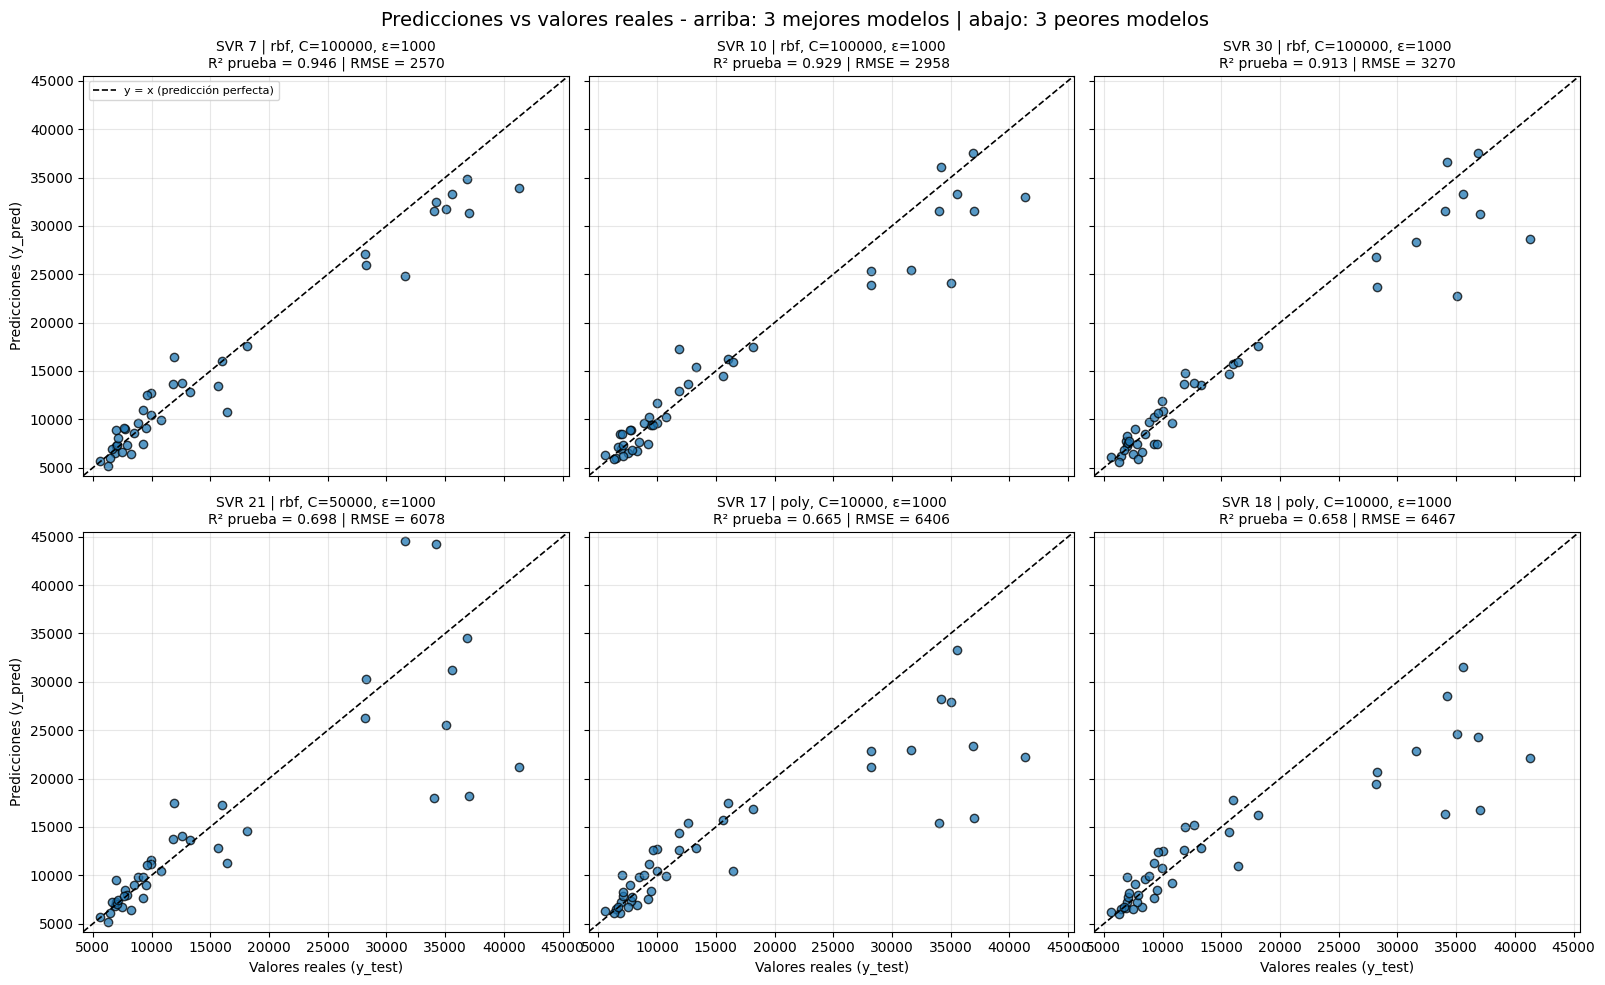

In [ ]:
# Seleccionar los 3 mejores y los 3 peores modelos
seleccion = (
    tabla.head(3)["algoritmo"].tolist()
    + tabla.tail(3)["algoritmo"].tolist()
)

info = tabla.set_index("algoritmo")

# Límites iguales para todas las gráficas
todos = np.concatenate([
    np.r_[predicciones[n][0], predicciones[n][1]]
    for n in seleccion
])

lim = (todos.min() - 1000, todos.max() + 1000)

# Crear las 6 gráficas
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

for ax, nombre in zip(axes.flat, seleccion):

    y_test, y_pred = predicciones[nombre]

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.75,
        edgecolor="k"
    )

    ax.plot(
        lim,
        lim,
        "k--",
        lw=1.2,
        label="y = x (predicción perfecta)"
    )

    ax.set_xlim(lim)
    ax.set_ylim(lim)

    ax.set_title(
        f"{nombre} | {info.loc[nombre, 'kernel']}, "
        f"C={info.loc[nombre, 'C']:g}, "
        f"ε={info.loc[nombre, 'epsilon']:g}\n"
        f"R² prueba = {info.loc[nombre, 'r2_test']:.3f} | "
        f"RMSE = {info.loc[nombre, 'rmse']:.0f}",
        fontsize=10
    )

    ax.grid(alpha=0.3)

for ax in axes[1]:
    ax.set_xlabel("Valores reales (y_test)")

for ax in axes[:, 0]:
    ax.set_ylabel("Predicciones (y_pred)")

axes[0, 0].legend(fontsize=8, loc="upper left")

fig.suptitle(
    "Predicciones vs valores reales - arriba: 3 mejores modelos | abajo: 3 peores modelos",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 6. Actividad de Reflexión

### 1. Interpretación de métricas

**a. ¿Por qué un modelo con R² más bajo puede ser más confiable que uno con R² muy alto?**

Un R² muy alto no garantiza por sí solo que un modelo sea mejor. Si obtiene un R² muy alto en entrenamiento pero disminuye considerablemente al utilizar datos de prueba, puede indicar sobreajuste. Un modelo con un R² ligeramente menor, pero con resultados similares entre entrenamiento y prueba, puede ser más confiable porque muestra una mejor capacidad de generalización.

**b. ¿Qué significa que el RMSE sea más alto en un modelo que en otro?**

Un RMSE más alto indica que existe una mayor diferencia entre los valores reales y los valores predichos. Por lo tanto, al comparar modelos sobre los mismos datos, un RMSE menor representa generalmente una mayor precisión en las predicciones.

En los modelos evaluados, el SVR 7 obtuvo el menor RMSE entre los tres mejores modelos, con aproximadamente 2570.12, mientras que el SVR 18 alcanzó aproximadamente 6466.63 y se ubicó como el modelo con menor desempeño.

**c. ¿Cómo identificar si un modelo está sobreajustado o subajustado?**

El sobreajuste puede identificarse cuando un modelo obtiene un desempeño muy alto en entrenamiento, pero considerablemente menor en prueba. El subajuste ocurre cuando el desempeño es bajo tanto en entrenamiento como en prueba.

En los resultados obtenidos, el SVR 7 presentó un R² de entrenamiento de 0.9429 y un R² de prueba de 0.9460, por lo que no se observa una señal evidente de sobreajuste y presenta una buena capacidad de generalización.

### 2. Impacto de las variables

**a. ¿Qué pasaría si el dataset incluyera más variables relacionadas con el mercado, como marca, año o tipo de combustible?**

La incorporación de nuevas variables podría mejorar la capacidad predictiva del modelo si estas tienen una relación importante con el precio del automóvil. Por ejemplo, la marca, el año del vehículo o el tipo de combustible pueden influir directamente en su valor.

Sin embargo, agregar más variables no garantiza automáticamente un mejor resultado. Si se incorporan características poco relevantes o redundantes, el modelo puede volverse más complejo sin mejorar su capacidad de predicción.

**b. ¿Qué variables parecen ser más importantes para predecir el precio y por qué?**

De acuerdo con los resultados obtenidos, variables como `horsepower`, `engine-size` y `curb-weight` parecen tener una relación importante con la predicción del precio, ya que aparecen de manera recurrente en los modelos con mejor desempeño.

El mejor modelo, SVR 7, utilizó `horsepower`, `engine-size`, `curb-weight`, `width` y `length`, alcanzando un R² de prueba de 0.9460 y un RMSE de 2570.12.

Esto sugiere que combinar características relacionadas con la potencia, el tamaño del motor, el peso y las dimensiones del automóvil permite obtener buenas predicciones del precio.

**c. ¿Cómo afecta agregar o eliminar variables al desempeño del modelo?**

Los resultados muestran que el desempeño depende de la combinación de variables y no solamente de utilizar una mayor cantidad.

Por ejemplo, el SVR 7 utilizó cinco variables y obtuvo el mejor R² de prueba, con 0.9460. En cambio, el SVR 10 utilizó una cantidad mayor de variables y obtuvo un R² de prueba de 0.9285.

También se observó que el SVR 21, que utilizó únicamente `curb-weight`, `width`, `length` y `wheel-base`, obtuvo un R² de prueba de 0.6981. Esto indica que eliminar variables relacionadas con características como la potencia y el tamaño del motor puede reducir la capacidad predictiva.

Por lo tanto, seleccionar variables relevantes puede ser más importante que simplemente utilizar una mayor cantidad de características.

### 3. Ajuste de parámetros

**¿Qué parámetros podrían modificarse para mejorar el desempeño del modelo?**

En SVR se pueden modificar principalmente parámetros como `C`, `epsilon`, `gamma` y el tipo de `kernel`.

En los modelos evaluados se probaron diferentes valores de estos parámetros. Los tres mejores modelos utilizaron kernel RBF y un valor de C de 100000, mientras que dos de los modelos con menor desempeño utilizaron kernel polinómico.

El parámetro `C` controla la penalización de los errores, `epsilon` establece un margen de tolerancia en las predicciones y `gamma` influye en el comportamiento del kernel RBF. Por esta razón, probar diferentes combinaciones de estos parámetros puede ayudar a encontrar una configuración con mejor capacidad de generalización.

### 4. Selección del algoritmo de regresión

**¿Cómo se puede determinar qué algoritmo de regresión utilizar?**

La elección del algoritmo depende de las características del dataset, la relación entre las variables y el objetivo del problema. No existe un algoritmo que sea el mejor para todos los casos, por lo que es necesario entrenar y comparar diferentes alternativas utilizando las mismas condiciones y métricas de evaluación.

Para realizar la comparación pueden utilizarse métricas como R², MSE y RMSE, además de analizar la diferencia entre el desempeño en entrenamiento y prueba. También deben considerarse aspectos como la cantidad de datos, la complejidad del modelo y su capacidad de generalización.

En el caso de SVR, los resultados obtenidos muestran que diferentes kernels, variables y parámetros pueden producir cambios importantes en el desempeño, por lo que la experimentación y comparación de configuraciones resulta fundamental.

### 5. Modelos complejos frente a modelos simples

**¿Cuáles son las ventajas y desventajas de utilizar un modelo complejo frente a uno simple?**

Un modelo más complejo puede identificar relaciones y patrones que un modelo simple podría no representar adecuadamente, lo que puede mejorar las predicciones cuando los datos presentan relaciones no lineales.

Sin embargo, una mayor complejidad también puede aumentar el riesgo de sobreajuste y dificultar la interpretación y el ajuste del modelo. Por otro lado, los modelos simples suelen ser más fáciles de interpretar y requieren menos ajustes, aunque pueden presentar subajuste si no logran representar correctamente el comportamiento de los datos.

Por esta razón, el modelo más complejo no necesariamente será el mejor. Lo importante es encontrar un equilibrio entre desempeño, generalización y complejidad.

### 6. Impacto de un dataset más grande

**¿Qué impacto tendría utilizar un dataset con una mayor cantidad de datos?**

Un dataset más grande podría ayudar al modelo a identificar patrones de manera más confiable y mejorar su capacidad de generalización, ya que tendría una mayor cantidad de ejemplos para aprender.

También permitiría evaluar el modelo con una muestra de prueba más representativa. En este caso se trabajó con 201 registros, por lo que aumentar la cantidad de automóviles podría proporcionar una mayor variedad de precios y características.

Sin embargo, una mayor cantidad de datos también puede aumentar el tiempo y los recursos necesarios para el entrenamiento, especialmente al probar múltiples configuraciones de SVR.

### 7. Aplicación de los modelos en otros contextos

**¿Cómo podrían aplicarse estos modelos de regresión en otros contextos?**

Los modelos de regresión pueden utilizarse en diferentes problemas donde el objetivo sea predecir un valor numérico a partir de distintas características.

Por ejemplo, podrían utilizarse para estimar el precio de viviendas a partir de su ubicación, tamaño y número de habitaciones; predecir ventas de productos utilizando información histórica; estimar el consumo de energía; o calcular tiempos y costos de transporte.

El procedimiento sería similar al realizado en esta práctica: seleccionar las variables relevantes, preparar los datos, entrenar diferentes configuraciones, evaluar sus métricas y seleccionar el modelo con mejor capacidad de generalización.

## 7. Preguntas adicionales generadas con apoyo de IAG

### 1. ¿Por qué es importante escalar las variables antes de entrenar un modelo SVR?

El escalamiento es importante porque las variables pueden encontrarse en rangos muy diferentes. Por ejemplo, `horsepower`, `engine-size` y `curb-weight` manejan magnitudes distintas.

SVR trabaja con distancias entre los datos, por lo que una variable con valores numéricos mucho mayores podría tener una influencia desproporcionada. Por esta razón, en los modelos desarrollados se utilizó `StandardScaler` antes del entrenamiento.

### 2. ¿Cómo influye el tipo de kernel en el desempeño de un modelo SVR?

El kernel determina la manera en que SVR representa la relación entre las variables predictoras y la variable objetivo. Un kernel lineal busca relaciones más simples, mientras que kernels como RBF y polinómico permiten representar relaciones no lineales.

En los resultados obtenidos, los tres mejores modelos utilizaron kernel RBF. En cambio, SVR 17 y SVR 18, que utilizaron kernel polinómico, se ubicaron entre los tres modelos con menor desempeño. Esto muestra que, para las configuraciones evaluadas en este dataset, el kernel RBF produjo mejores resultados.

### 3. ¿Por qué el SVR 7 obtuvo un mejor resultado que modelos que utilizaron más variables?

Utilizar una mayor cantidad de variables no garantiza un mejor desempeño. El SVR 7 utilizó cinco variables: `horsepower`, `engine-size`, `curb-weight`, `width` y `length`, obteniendo un R² de prueba de 0.9460.

Por otro lado, el SVR 10 utilizó una mayor cantidad de variables y obtuvo un R² de prueba de 0.9285. Esto indica que una combinación adecuada de variables relevantes puede producir mejores resultados que simplemente agregar más características al modelo.

### 4. ¿Qué indica que el R² de prueba del SVR 7 sea ligeramente mayor que su R² de entrenamiento?

El SVR 7 obtuvo un R² de entrenamiento de 0.9429 y un R² de prueba de 0.9460. La diferencia es muy pequeña, por lo que no representa por sí sola un problema.

Esto puede ocurrir debido a la división específica de los datos utilizada para entrenamiento y prueba. Lo importante es que ambos valores son altos y muy similares, lo que indica que el modelo mantiene un buen desempeño con datos que no utilizó durante el entrenamiento.

### 5. ¿Qué podría hacerse para comprobar que el buen resultado del SVR 7 no depende únicamente de la división de los datos?

Una opción sería utilizar validación cruzada. Esta técnica divide el dataset de diferentes maneras y evalúa el modelo varias veces, en lugar de depender únicamente de una división fija de entrenamiento y prueba.

De esta manera se podría comprobar si el SVR 7 mantiene un buen desempeño en diferentes subconjuntos de datos y obtener una evaluación más robusta de su capacidad de generalización.